# Imports

In [1]:
import os

cwd = os.getcwd()
os.chdir("/home/yoshi0428/PycharmProjects/osu-predict")

In [2]:
import json
import pickle
from collections import Counter
from datetime import datetime

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GroupKFold,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from beatmap_classifier.classifier.augment_faster import (
    augment_dataset,
    extract_movement_features_from_X,
)
from beatmap_classifier.classifier.cnn_model import CNNModel
from beatmap_classifier.classifier.utils_training import (
    get_additional_features,
    get_data,
    load_pytorch_models,
    pad_sequences_pt,
    plot_training_history,
    save_vector_normalization,
    train_and_evaluate,
)

# Model Testing

Go run test_model.py

# Initializing some Data

In [3]:
TOURNAMENT_MODS = {
    "nm1": "NM",
    "nm2": "NM",
    "nm3": "NM",
    "nm4": "NM",
    "nm5": "NM",
    "nm6": "NM",
    "hd1": "HD",
    "hd2": "HD",
    "hd3": "HD",
    "hr1": "HR",
    "hr2": "HR",
    "hr3": "HR",
    "dt1": "DT",
    "dt2_and_dt3": "DT",
    "dt4": "DT",
    "tiebreaker": "NM",
}

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

db_path = "./beatmap_classifier/beatmaps.db"

X, y, beatmap_ids = get_data(db_path)
raw_additional_features, normalized_additional_features = get_additional_features(
    db_path, y, beatmap_ids
)

# Precompute must scale vectors exactly like get_data() did, so save the
# scales next to the model (read by precompute_nm1-5.py and test_model.py).
save_vector_normalization(db_path, "./beatmap_classifier/models/eval/vector_normalization.json")

Max Vector Length: 500.0
Max Time Diff: 86087.0
Tournament-labeled beatmaps: 3922
Max Vector Count: 6309
Original beatmaps: 3922


In [5]:
# Get the mod associated with each tournament label
mods_flattened = [
    TOURNAMENT_MODS[label] if TOURNAMENT_MODS[label] else "NM" for label in y
]

raw_additional_features_array = np.array(
    [
        raw_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

normalized_additional_features_array = np.array(
    [
        normalized_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

In [6]:
(
    X_train,
    X_test,
    y_train,
    y_test,
    beatmap_ids_train,
    beatmap_ids_test,
) = train_test_split(
    X,
    y,
    beatmap_ids,
    test_size=0.2,
    random_state=42,
)

print(f"Final train size: {len(X_train)}")
print(f"Final test size:  {len(X_test)}")

Final train size: 3137
Final test size:  785


In [7]:
# Encode labels
label_encoder = LabelEncoder()
label_encoder.fit(y)

with open("./beatmap_classifier/models/eval/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

y_train_numerical = label_encoder.transform(y_train)
y_test_numerical = label_encoder.transform(y_test)
num_classes = len(label_encoder.classes_)

y_train_numerical = torch.tensor(y_train_numerical, dtype=torch.long)
y_test_numerical = torch.tensor(y_test_numerical, dtype=torch.long)

# Pad sequences
sequence_lengths = np.array([len(seq) for seq in X])
max_length = int(np.percentile(sequence_lengths, 99))
max_length = 2 ** int(np.ceil(np.log2(max_length)))
max_length = min(max_length, 4096)

print(f"Using max sequence length: {max_length}")

X_train = pad_sequences_pt(X_train, maxlen=max_length, dtype=torch.float32)

X_test = pad_sequences_pt(X_test, maxlen=max_length, dtype=torch.float32)

print("Before metadata:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

Using max sequence length: 4096
Before metadata:
X_train: torch.Size([3137, 4096, 8])
X_test:  torch.Size([785, 4096, 8])


In [8]:
class_counts = Counter(y_train_numerical.numpy())

for cls, count in sorted(class_counts.items()):
    print(f"Class {cls}: {count}")

print(dict(enumerate(label_encoder.classes_)))

Class 0: 703
Class 1: 710
Class 2: 731
Class 3: 608
Class 4: 385
{0: np.str_('nm1'), 1: np.str_('nm2'), 2: np.str_('nm3'), 3: np.str_('nm4'), 4: np.str_('nm5')}


In [9]:
# Extract geometric summary vectors for each row in X_train and X_test
movement_features_train = np.array(
    [extract_movement_features_from_X(X_train[i]) for i in range(len(X_train))],
    dtype=np.float32,
)

movement_features_test = np.array(
    [extract_movement_features_from_X(X_test[i]) for i in range(len(X_test))],
    dtype=np.float32,
)

# NOTICE THAT WE SWITCH FROM NORMALIZED TO RAW ADDITIONAL FEATURES
# BECAUSE XGBOOST DOESN'T NEED SCALING

# Extract SQLite metadata features corresponding to train/test IDs
mods_flattened_train = [TOURNAMENT_MODS.get(label, "NM") for label in y_train]

sql_features_train = np.array(
    [
        raw_additional_features[(b_id, mod)]
        for b_id, mod in zip(beatmap_ids_train, mods_flattened_train)
    ],
    dtype=np.float32,
)

mods_flattened_test = [TOURNAMENT_MODS.get(label, "NM") for label in y_test]

sql_features_test = np.array(
    [
        raw_additional_features.get((b_id, mod))
        for b_id, mod in zip(beatmap_ids_test, mods_flattened_test)
    ],
    dtype=np.float32,
)

# Concatenate (SQL metadata + Movement geometric summary)
X_additional_train = np.hstack([sql_features_train, movement_features_train])
X_additional_test = np.hstack([sql_features_test, movement_features_test])

print(f"Full meta tabular train shape: {X_additional_train.shape}")
print(f"Full meta tabular test shape:  {X_additional_test.shape}")

Full meta tabular train shape: (3137, 24)
Full meta tabular test shape:  (785, 24)


# CNN Model (SKIP TO XGBOOST IF DESIRED)

--- Training Meta Fold 1/5 ---
Original samples: 2509 -> Augmented total: 10036
Epoch 1/50 - loss: 2.6592 - acc: 0.3808 - val_loss: 1.1616 - val_acc: 0.6385
Epoch 2/50 - loss: 1.3006 - acc: 0.5170 - val_loss: 1.0719 - val_acc: 0.6752
Epoch 3/50 - loss: 1.2222 - acc: 0.5626 - val_loss: 1.0382 - val_acc: 0.7054
Epoch 4/50 - loss: 1.1786 - acc: 0.5957 - val_loss: 0.9972 - val_acc: 0.7261
Epoch 5/50 - loss: 1.1434 - acc: 0.6101 - val_loss: 0.9851 - val_acc: 0.7150
Epoch 6/50 - loss: 1.1178 - acc: 0.6309 - val_loss: 0.9384 - val_acc: 0.7357
Epoch 7/50 - loss: 1.1000 - acc: 0.6393 - val_loss: 0.9386 - val_acc: 0.7404
Epoch 8/50 - loss: 1.0874 - acc: 0.6398 - val_loss: 0.9124 - val_acc: 0.7484
Epoch 9/50 - loss: 1.0661 - acc: 0.6613 - val_loss: 0.9072 - val_acc: 0.7548
Epoch 10/50 - loss: 1.0512 - acc: 0.6619 - val_loss: 0.9152 - val_acc: 0.7516
Epoch 11/50 - loss: 1.0218 - acc: 0.6870 - val_loss: 0.8729 - val_acc: 0.7739
Epoch 12/50 - loss: 1.0100 - acc: 0.6899 - val_loss: 0.8723 - val_acc: 

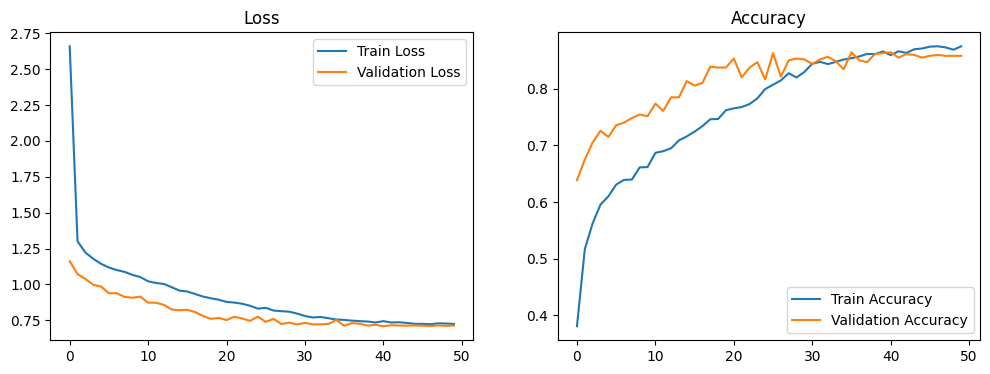

--- Training Meta Fold 2/5 ---
Original samples: 2509 -> Augmented total: 10036
Epoch 1/50 - loss: 2.2520 - acc: 0.4266 - val_loss: 1.1285 - val_acc: 0.6465
Epoch 2/50 - loss: 1.2194 - acc: 0.5615 - val_loss: 1.0779 - val_acc: 0.6433
Epoch 3/50 - loss: 1.1528 - acc: 0.6044 - val_loss: 0.9984 - val_acc: 0.7166
Epoch 4/50 - loss: 1.1121 - acc: 0.6324 - val_loss: 0.9668 - val_acc: 0.7436
Epoch 5/50 - loss: 1.0760 - acc: 0.6550 - val_loss: 0.9532 - val_acc: 0.7516
Epoch 6/50 - loss: 1.0487 - acc: 0.6731 - val_loss: 0.9360 - val_acc: 0.7532
Epoch 7/50 - loss: 1.0359 - acc: 0.6817 - val_loss: 0.9395 - val_acc: 0.7468
Epoch 8/50 - loss: 1.0116 - acc: 0.6984 - val_loss: 0.8975 - val_acc: 0.7723
Epoch 9/50 - loss: 1.0070 - acc: 0.6976 - val_loss: 0.8950 - val_acc: 0.7723
Epoch 10/50 - loss: 0.9873 - acc: 0.7052 - val_loss: 0.8787 - val_acc: 0.7691
Epoch 11/50 - loss: 0.9736 - acc: 0.7120 - val_loss: 0.8829 - val_acc: 0.7882
Epoch 12/50 - loss: 0.9662 - acc: 0.7180 - val_loss: 0.8599 - val_acc: 

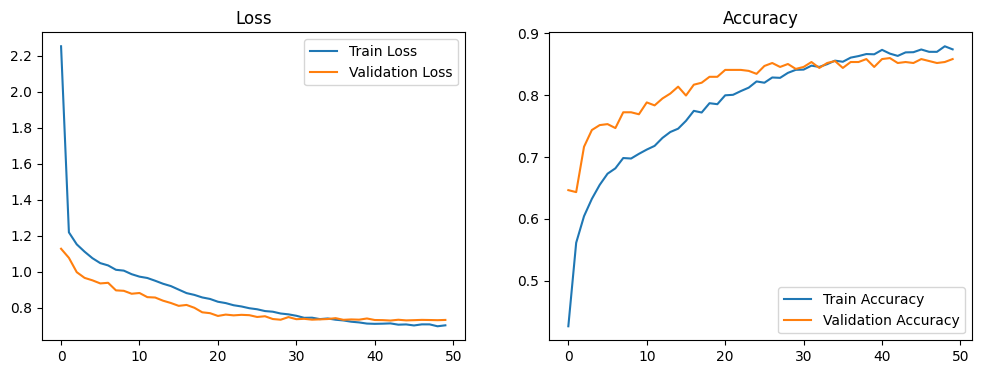

--- Training Meta Fold 3/5 ---
Original samples: 2510 -> Augmented total: 10040
Epoch 1/50 - loss: 3.1131 - acc: 0.4168 - val_loss: 1.1804 - val_acc: 0.6348
Epoch 2/50 - loss: 1.2647 - acc: 0.5553 - val_loss: 1.0762 - val_acc: 0.6874
Epoch 3/50 - loss: 1.1942 - acc: 0.5877 - val_loss: 1.0017 - val_acc: 0.7177
Epoch 4/50 - loss: 1.1410 - acc: 0.6145 - val_loss: 0.9709 - val_acc: 0.7177
Epoch 5/50 - loss: 1.1065 - acc: 0.6389 - val_loss: 0.9575 - val_acc: 0.7033
Epoch 6/50 - loss: 1.0917 - acc: 0.6540 - val_loss: 0.9556 - val_acc: 0.7289
Epoch 7/50 - loss: 1.0623 - acc: 0.6654 - val_loss: 0.9335 - val_acc: 0.7321
Epoch 8/50 - loss: 1.0506 - acc: 0.6746 - val_loss: 0.9365 - val_acc: 0.7352
Epoch 9/50 - loss: 1.0436 - acc: 0.6823 - val_loss: 0.9236 - val_acc: 0.7464
Epoch 10/50 - loss: 1.0233 - acc: 0.6867 - val_loss: 0.9079 - val_acc: 0.7480
Epoch 11/50 - loss: 1.0051 - acc: 0.6990 - val_loss: 0.9098 - val_acc: 0.7608
Epoch 12/50 - loss: 1.0043 - acc: 0.7022 - val_loss: 0.8976 - val_acc: 

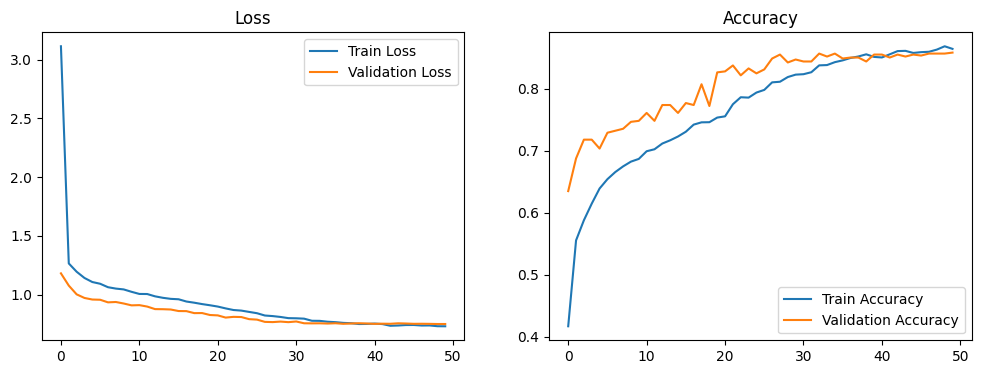

--- Training Meta Fold 4/5 ---
Original samples: 2510 -> Augmented total: 10040
Epoch 1/50 - loss: 2.8380 - acc: 0.4552 - val_loss: 1.1274 - val_acc: 0.6284
Epoch 2/50 - loss: 1.2246 - acc: 0.5778 - val_loss: 1.0335 - val_acc: 0.6842
Epoch 3/50 - loss: 1.1763 - acc: 0.6012 - val_loss: 1.0325 - val_acc: 0.6906
Epoch 4/50 - loss: 1.1317 - acc: 0.6295 - val_loss: 1.0105 - val_acc: 0.6970
Epoch 5/50 - loss: 1.1054 - acc: 0.6487 - val_loss: 0.9781 - val_acc: 0.7113
Epoch 6/50 - loss: 1.0787 - acc: 0.6579 - val_loss: 0.9660 - val_acc: 0.7289
Epoch 7/50 - loss: 1.0548 - acc: 0.6725 - val_loss: 0.9491 - val_acc: 0.7384
Epoch 8/50 - loss: 1.0338 - acc: 0.6875 - val_loss: 0.9554 - val_acc: 0.7177
Epoch 9/50 - loss: 1.0037 - acc: 0.7014 - val_loss: 0.9206 - val_acc: 0.7368
Epoch 10/50 - loss: 0.9949 - acc: 0.7041 - val_loss: 0.8982 - val_acc: 0.7592
Epoch 11/50 - loss: 0.9780 - acc: 0.7169 - val_loss: 0.8812 - val_acc: 0.7735
Epoch 12/50 - loss: 0.9528 - acc: 0.7288 - val_loss: 0.8809 - val_acc: 

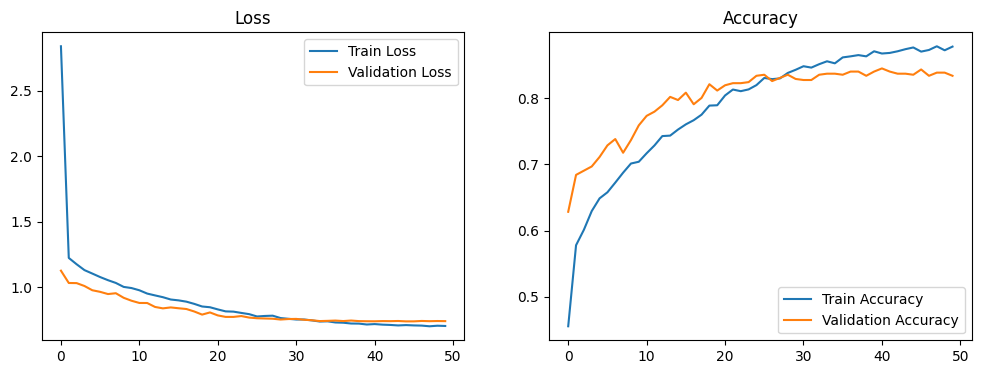

--- Training Meta Fold 5/5 ---
Original samples: 2510 -> Augmented total: 10040
Epoch 1/50 - loss: 2.4794 - acc: 0.4199 - val_loss: 1.1997 - val_acc: 0.6236
Epoch 2/50 - loss: 1.2639 - acc: 0.5512 - val_loss: 1.0646 - val_acc: 0.6986
Epoch 3/50 - loss: 1.1800 - acc: 0.5982 - val_loss: 1.0194 - val_acc: 0.7129
Epoch 4/50 - loss: 1.1301 - acc: 0.6278 - val_loss: 0.9777 - val_acc: 0.7209
Epoch 5/50 - loss: 1.0990 - acc: 0.6506 - val_loss: 0.9659 - val_acc: 0.7464
Epoch 6/50 - loss: 1.0701 - acc: 0.6645 - val_loss: 0.9403 - val_acc: 0.7512
Epoch 7/50 - loss: 1.0571 - acc: 0.6673 - val_loss: 0.9564 - val_acc: 0.7289
Epoch 8/50 - loss: 1.0388 - acc: 0.6779 - val_loss: 0.9069 - val_acc: 0.7767
Epoch 9/50 - loss: 1.0063 - acc: 0.6969 - val_loss: 0.9023 - val_acc: 0.7815
Epoch 10/50 - loss: 0.9913 - acc: 0.7095 - val_loss: 0.8752 - val_acc: 0.7831
Epoch 11/50 - loss: 0.9718 - acc: 0.7209 - val_loss: 0.8673 - val_acc: 0.7799
Epoch 12/50 - loss: 0.9563 - acc: 0.7333 - val_loss: 0.9150 - val_acc: 

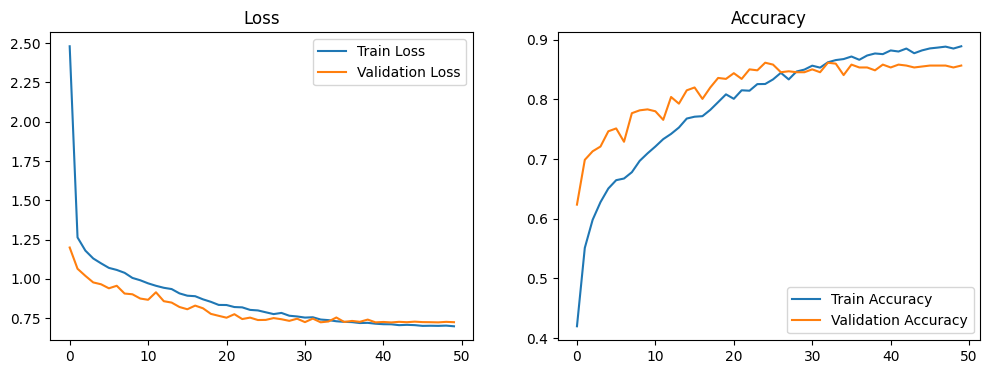

In [10]:
meta_bagging_models = []
beatmap_ids_train = np.array(beatmap_ids_train)

# Initialize empty matrix for clean Out-Of-Fold CNN probability predictions
oof_cnn_predictions = np.zeros((len(X_train), num_classes), dtype=np.float32)

# Use GroupKFold so mapset difficulties stay grouped
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X_train, y_train_numerical, groups=beatmap_ids_train)
):
    print(f"--- Training Meta Fold {fold + 1}/5 ---")

    # Split raw unaugmented fold data
    X_fold_train, y_fold_train = X_train[train_idx], y_train_numerical[train_idx]
    X_fold_val, y_fold_val = X_train[val_idx], y_train_numerical[val_idx]
    beatmap_ids_fold_train = beatmap_ids_train[train_idx]

    # Augment ONLY the training fold
    X_fold_train_aug, y_fold_train_aug, _ = augment_dataset(
        X_fold_train,
        y_fold_train,
        beatmap_ids_fold_train,
        augmentation_types={"horizontal", "vertical", "horizontal_vertical"},
    )

    # Convert validation fold to PyTorch Tensor (permuted to (B, C, L))
    X_fold_val = torch.as_tensor(X_fold_val, dtype=torch.float32).permute(0, 2, 1)
    y_fold_val = torch.as_tensor(y_fold_val, dtype=torch.long)

    X_fold_train_aug = X_fold_train_aug.permute(0, 2, 1)

    # Train CNN model for this fold
    model, history = train_and_evaluate(
        X_fold_train_aug,
        y_fold_train_aug,
        X_fold_val,
        y_fold_val,
        input_channels=X_fold_train_aug.shape[1],
        num_classes=num_classes,
        max_length=max_length,
        learning_rate=0.001,
        dropout_rate=0.5,  # old: 0.5
        l2_reg=0.001,
        batch_size=128,
        epochs=50,  # old: 30
        patience=15,
    )
    plot_training_history(history)
    meta_bagging_models.append(model)

    # Generate Out-of-Fold predictions for the unaugmented validation set ONLY
    model.eval()
    with torch.no_grad():
        val_inputs = X_fold_val.to(device)
        logits = model(val_inputs)
        probs = torch.softmax(logits, dim=1).cpu().numpy()

    # Store clean OOF predictions in the array
    oof_cnn_predictions[val_idx] = probs

In [11]:
os.makedirs("./beatmap_classifier/models/eval/bagged_models", exist_ok=True)

for i, model in enumerate(meta_bagging_models):
    torch.save(model.state_dict(), f"./beatmap_classifier/models/eval/bagged_models/bagged_cnn_model_{i}.pth")

np.save("./beatmap_classifier/models/eval/oof_cnn_predictions.npy", oof_cnn_predictions)
np.save("./beatmap_classifier/models/eval/y_train_numerical.npy", y_train_numerical)
np.save("./beatmap_classifier/models/eval/beatmap_ids_train.npy", np.array(beatmap_ids_train))

# XGBoost Meta Model

### Load Models and Data

In [12]:
model_kwargs = {
    "input_channels": 8,
    "num_classes": num_classes,
    "max_length": max_length,
    "dropout_rate": 0.5,
}

meta_bagging_models = load_pytorch_models(
    model_folder="./beatmap_classifier/models/eval/bagged_models",
    model_class=CNNModel,
    model_kwargs=model_kwargs,
    device=device,
)

oof_cnn_predictions = np.load("./beatmap_classifier/models/eval/oof_cnn_predictions.npy")
y_train_numerical = np.load("./beatmap_classifier/models/eval/y_train_numerical.npy")

print(f"Loaded {len(meta_bagging_models)} CNN models")

Loaded 5 CNN models


### Test the bagging models
87% is already pretty good, but we will see soon that we can improve it

In [13]:
# Generate Test probabilities by averaging predictions across all fold models
X_test_tensor = torch.as_tensor(X_test, dtype=torch.float32).permute(0, 2, 1).to(device)
test_probs_list = []

for model in meta_bagging_models:
    model.eval()
    with torch.no_grad():
        logits = model(X_test_tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        test_probs_list.append(probs)

bagged_test_predictions = np.mean(test_probs_list, axis=0)
bagged_test_predictions_numerical = np.argmax(bagged_test_predictions, axis=1)

score = accuracy_score(y_test_numerical, bagged_test_predictions_numerical)
cm = confusion_matrix(y_test_numerical, bagged_test_predictions_numerical)
report = classification_report(
    y_test_numerical,
    bagged_test_predictions_numerical,
    zero_division=0,
    target_names=[
        "NM1",
        "NM2",
        "NM3",
        "NM4",
        "NM5",
    ],  # "DT1", "DT2_and_DT3", "HD2", "HR1", "HR2",
)

print("Classification Report:\n", report)
print("Confusion Matrix:\n", cm)
print(f"Accuracy: {score}")

Classification Report:
               precision    recall  f1-score   support

         NM1       0.94      0.93      0.94       192
         NM2       0.84      0.93      0.89       158
         NM3       0.86      0.87      0.86       186
         NM4       0.83      0.82      0.83       153
         NM5       0.83      0.72      0.77        96

    accuracy                           0.87       785
   macro avg       0.86      0.85      0.86       785
weighted avg       0.87      0.87      0.87       785

Confusion Matrix:
 [[179   0   9   3   1]
 [  0 147   2   0   9]
 [  6   2 161  16   1]
 [  2   8  14 126   3]
 [  3  17   1   6  69]]
Accuracy: 0.8687898089171975


### Setup

Make sure that this setup matches in `/beatmap_recommender/recommender_db_setup/precompute_nm1-5.py` whenever you're done.

In [14]:
sql_feature_names = [
    "ar",
    "od",
    "circle_size",
    "star_rating",
    "bpm",
    "max_combo",
    "length_seconds",
    "object_count",
    "pp",
    "pp_aim",
    "pp_speed",
    "pp_acc",
]

movement_feature_names = [
    "slider_ratio",
    "slider_length_std",
    "speed_std",
    "speed_change_std",
    "speed_change_max",
    "angle_std",
    "angle_mean",
    "rhythm_variance",
    "distance_mean",
    "speed_change_95th",
    "angle_90th",
    "sharp_turn_ratio",
]

cnn_feature_names = [
    "CNN_NM1",
    "CNN_NM2",
    "CNN_NM3",
    "CNN_NM4",
    "CNN_NM5",
]

additional_feature_names = sql_feature_names + movement_feature_names

In [15]:
print(additional_feature_names)

['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']


You can add more feature groups here, if desired

In [16]:
# GROUP 1
excluded_features = {
}

group1_features = [
    feature for feature in additional_feature_names if feature not in excluded_features
]

# GROUP 2
# excluded_features = {
#     "speed_change_95th",
# }
#
# group2_features = [
#     feature
#     for feature in additional_feature_names
#     if feature not in excluded_features
# ]
#

# COMBINE ALL GROUPS TOGETHER
additional_feature_groups = {
    "group1": group1_features,
    # "group2": group2_features,
}

feature_indices = {
    group_name: [additional_feature_names.index(feature) for feature in features]
    for group_name, features in additional_feature_groups.items()
}

In [17]:
def make_xgb(params):
    return XGBClassifier(
        random_state=42,
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss",
        **params,
    )


def optimize_xgb_feature_set(
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    indices,
    n_trials=50,
    seed=42,
):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 250, 750, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        }

        scores = []

        for train_idx, valid_idx in cv.split(X_meta_train, y_train):
            X_train = X_meta_train[train_idx]
            X_valid = X_meta_train[valid_idx]

            y_train_fold = y_train[train_idx]
            y_valid_fold = y_train[valid_idx]

            model = make_xgb(params)
            model.fit(
                X_train, y_train_fold, eval_set=[(X_valid, y_valid_fold)], verbose=False
            )
            pred = model.predict(X_valid)

            scores.append(
                f1_score(y_valid_fold, pred, average="macro", zero_division=0)
            )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study


def cv_evaluate_feature_set(
    indices,
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    params,
    seed=42,
):
    # Scores a feature set with CV on the train split only, so feature selection
    # never sees the test set
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    pred = cross_val_predict(make_xgb(params), X_meta_train, y_train, cv=cv)

    cm = confusion_matrix(y_train, pred)

    return {
        "accuracy": accuracy_score(y_train, pred),
        "macro_f1": f1_score(y_train, pred, average="macro"),
        "nm3_to_nm4": cm[2, 3],
        "nm4_to_nm3": cm[3, 2],
    }


def fit_meta_model(indices, X_additional_train, oof_cnn_predictions, y_train, params):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    model = make_xgb(params)
    model.fit(X_meta_train, y_train)
    return model

In [18]:
def get_feature_indices(feature_names, selected_features):
    missing = [name for name in selected_features if name not in feature_names]

    if missing:
        raise ValueError(f"Features not found: {missing}")

    return [feature_names.index(name) for name in selected_features]

### Compare the XGBoost Classifiers within Feature Groups

Skip this cell if you're trying to compared changed features, and already obtained some good params in `./models/xgb_best_params.json`

Change n_trials if needed.

In [19]:
studies = {}
best_params = {}

for group_name, indices in feature_indices.items():
    study = optimize_xgb_feature_set(
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        indices=indices,
        n_trials=100,
    )

    studies[group_name] = study

    best_params[group_name] = {
        "macro_f1": study.best_value,
        "params": study.best_params,
    }

    print(f"\nBest macro F1: {study.best_value:.4f}")
    print("Best parameters:")

    for param, value in study.best_params.items():
        print(f"  {param}: {value}")

# Save this entire experiment as a new file
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = f"./beatmap_classifier/models/eval/xgb_params/xgb_best_params_{timestamp}.json"

with open(output_path, "w") as f:
    json.dump(best_params, f, indent=4)

print(f"\nSaved best parameters to: {output_path}")

[I 2026-10-12 13:00:26,086] A new study created in memory with name: no-name-cf90d977-a8d8-482e-8934-f8d2e2b7b338
Best trial: 0. Best value: 0.911554:   1%|          | 1/100 [00:03<05:54,  3.58s/it]

[I 2026-10-12 13:00:29,665] Trial 0 finished with value: 0.9115538706118844 and parameters: {'n_estimators': 450, 'learning_rate': 0.0862735828664018, 'max_depth': 7, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.0001707396743152812, 'reg_lambda': 5.3994844097874335}. Best is trial 0 with value: 0.9115538706118844.


Best trial: 0. Best value: 0.911554:   2%|▏         | 2/100 [00:06<04:49,  2.96s/it]

[I 2026-10-12 13:00:32,187] Trial 1 finished with value: 0.9081493159206758 and parameters: {'n_estimators': 550, 'learning_rate': 0.04170553216181044, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 0.000533703276260396, 'reg_lambda': 0.2327067708383781}. Best is trial 0 with value: 0.9115538706118844.


Best trial: 2. Best value: 0.915186:   3%|▎         | 3/100 [00:09<05:23,  3.34s/it]

...

[I 2026-10-12 13:08:38,119] Trial 97 finished with value: 0.9163401358601515 and parameters: {'n_estimators': 600, 'learning_rate': 0.010483734212653778, 'max_depth': 8, 'min_child_weight': 4, 'subsample': 0.9287861342384268, 'colsample_bytree': 0.736649386298132, 'reg_alpha': 0.00020340194481273174, 'reg_lambda': 0.47154563865865234}. Best is trial 11 with value: 0.9178125626251722.


Best trial: 11. Best value: 0.917813:  99%|█████████▉| 99/100 [08:19<00:07,  7.81s/it]

[I 2026-10-12 13:08:45,960] Trial 98 finished with value: 0.915520307740179 and parameters: {'n_estimators': 600, 'learning_rate': 0.009872753034790599, 'max_depth': 8, 'min_child_weight': 4, 'subsample': 0.9304079024617273, 'colsample_bytree': 0.7371898192828275, 'reg_alpha': 0.0001535563980264132, 'reg_lambda': 0.4807097410977319}. Best is trial 11 with value: 0.9178125626251722.


Best trial: 11. Best value: 0.917813: 100%|██████████| 100/100 [08:28<00:00,  5.08s/it]

[I 2026-10-12 13:08:54,141] Trial 99 finished with value: 0.9165910652536701 and parameters: {'n_estimators': 650, 'learning_rate': 0.008278340189819136, 'max_depth': 8, 'min_child_weight': 5, 'subsample': 0.9050823590506667, 'colsample_bytree': 0.693297456437419, 'reg_alpha': 0.0003324189962912305, 'reg_lambda': 0.3124156056314616}. Best is trial 11 with value: 0.9178125626251722.

Best macro F1: 0.9178
Best parameters:
  n_estimators: 350
  learning_rate: 0.022240842093846913
  max_depth: 6
  min_child_weight: 3
  subsample: 0.886588474674238
  colsample_bytree: 0.7595810005862157
  reg_alpha: 0.00343461663274141
  reg_lambda: 0.10748181915055818

Saved best parameters to: ./beatmap_classifier/models/eval/xgb_params/xgb_best_params_20261012_130854.json


### Compare the XGBoost Classifiers by removing single features in a Feature Group
NOTE: value maximized in previous cell is Macro F1 Score. The comparisons below are scored with 5-fold CV on the train split, so the test set stays untouched until the final cell.

We're gonna load the best params here.

In [20]:
JSON_FILE = "xgb_best_params_20261012_130854.json"

with open(f"./beatmap_classifier/models/eval/xgb_params/{JSON_FILE}", "r") as f:
    best_params = json.load(f)

best_params

{'group1': {'macro_f1': 0.9178125626251722,
  'params': {'n_estimators': 350,
   'learning_rate': 0.022240842093846913,
   'max_depth': 6,
   'min_child_weight': 3,
   'subsample': 0.886588474674238,
   'colsample_bytree': 0.7595810005862157,
   'reg_alpha': 0.00343461663274141,
   'reg_lambda': 0.10748181915055818}}}

In [21]:
for group_name, indices in feature_indices.items():
    params = best_params[group_name]["params"]

    print("=" * 80)
    print(f"FEATURE GROUP: {group_name}")
    print(f"Number of features: {len(indices)}")
    print(f"Features:")
    print([additional_feature_names[i] for i in indices])

    results = cv_evaluate_feature_set(
        indices=indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    print(
        f"cv_accuracy={results['accuracy'] * 100:.2f}% | "
        f"cv_macro_f1={results['macro_f1']:.4f}"
    )

FEATURE GROUP: group1
Number of features: 24
Features:
['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']
cv_accuracy=92.06% | cv_macro_f1=0.9177


Set the desired group from the JSON in `FEATURE_GROUP`.

You might want to go back and forth, iteratively removing features from the selected group after seeing this cell's results. Keep doing this until CV accuracy is maximized.

In [22]:
FEATURE_GROUP = "group1"

params = best_params[FEATURE_GROUP]["params"]
all_features = additional_feature_groups[FEATURE_GROUP]
indices = get_feature_indices(additional_feature_names, all_features)

# --------------------------------------------------------------
# Baseline
# --------------------------------------------------------------
baseline = cv_evaluate_feature_set(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

print("Baseline (CV on train):")
print(baseline)

baseline_acc = baseline["accuracy"]
baseline_f1 = baseline["macro_f1"]

# --------------------------------------------------------------
# Leave-one-feature-out evaluation
# --------------------------------------------------------------
array_results = []

for removed_feature in all_features:
    remaining_features = [
        feature for feature in all_features if feature != removed_feature
    ]

    remaining_indices = get_feature_indices(
        additional_feature_names, remaining_features
    )

    results = cv_evaluate_feature_set(
        indices=remaining_indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    dict_results = {
        "removed": removed_feature,
        "accuracy": results["accuracy"],
        "macro_f1": results["macro_f1"],
        "acc_delta": results["accuracy"] - baseline_acc,
        "f1_delta": results["macro_f1"] - baseline_f1,
        "nm3_to_nm4": results["nm3_to_nm4"],
        "nm4_to_nm3": results["nm4_to_nm3"],
    }

    array_results.append(dict_results)

results_df = pd.DataFrame(array_results)

results_df = results_df.sort_values("acc_delta", ascending=False)

print(results_df.to_string(index=False))
print("=" * 100)

Baseline (CV on train):
{'accuracy': 0.9206248007650621, 'macro_f1': 0.9177266334726282, 'nm3_to_nm4': np.int64(42), 'nm4_to_nm3': np.int64(30)}
          removed  accuracy  macro_f1  acc_delta  f1_delta  nm3_to_nm4  nm4_to_nm3
       angle_90th  0.919987  0.916833  -0.000638 -0.000894          40          32
           pp_acc  0.919350  0.916485  -0.001275 -0.001242          41          33
 speed_change_std  0.918712  0.915717  -0.001913 -0.002010          41          32
 speed_change_max  0.918712  0.915717  -0.001913 -0.002010          41          32
        max_combo  0.918393  0.915109  -0.002231 -0.002618          41          31
  rhythm_variance  0.918393  0.915095  -0.002231 -0.002632          41          32
     object_count  0.918075  0.914659  -0.002550 -0.003067          41          30
   length_seconds  0.918075  0.914761  -0.002550 -0.002965          40          29
       angle_mean  0.918075  0.914662  -0.002550 -0.003065          41          31
           pp_aim  0.9177

### Final Test Evaluation
Run this only once you're done selecting features above. The meta model is fit on the full train split, scored on the test set, and saved here.

In [23]:
# --------------------------------------------------------------
# Final meta-model performance
# --------------------------------------------------------------
meta_model = fit_meta_model(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

with open("./beatmap_classifier/models/eval/meta_model.pkl", "wb") as f:
    pickle.dump(meta_model, f)

X_meta_test = np.hstack(
    [
        bagged_test_predictions,
        X_additional_test[:, indices],
    ]
)

y_pred_meta = meta_model.predict(X_meta_test)
test_acc = accuracy_score(y_test_numerical, y_pred_meta)

print(f"--- XGBoost Meta-Model Performance ---")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%\n")

print("Classification Report:")
print(
    classification_report(
        y_test_numerical, y_pred_meta, target_names=["NM1", "NM2", "NM3", "NM4", "NM5"]
    )
)
print("Confusion Matrix:")
print(confusion_matrix(y_test_numerical, y_pred_meta))

--- XGBoost Meta-Model Performance ---
Final Test Accuracy: 93.50%

Classification Report:
              precision    recall  f1-score   support

         NM1       0.98      0.96      0.97       192
         NM2       0.89      0.96      0.93       158
         NM3       0.95      0.94      0.94       186
         NM4       0.92      0.92      0.92       153
         NM5       0.93      0.86      0.90        96

    accuracy                           0.94       785
   macro avg       0.93      0.93      0.93       785
weighted avg       0.94      0.94      0.94       785

Confusion Matrix:
[[185   0   2   4   1]
 [  0 152   1   1   4]
 [  3   2 174   7   0]
 [  0   6   6 140   1]
 [  1  10   1   1  83]]


# Analysis

In [24]:
importance = meta_model.feature_importances_
meta_model_features = cnn_feature_names + all_features

for name, value in sorted(
    zip(meta_model_features, importance), key=lambda x: x[1], reverse=True
):
    print(f"{name:30s} {value:.4f}")

CNN_NM1                        0.1665
CNN_NM2                        0.1588
CNN_NM3                        0.1186
CNN_NM4                        0.1144
bpm                            0.0617
CNN_NM5                        0.0577
sharp_turn_ratio               0.0448
distance_mean                  0.0428
angle_mean                     0.0281
slider_ratio                   0.0270
slider_length_std              0.0246
pp_speed                       0.0210
object_count                   0.0113
angle_std                      0.0109
speed_std                      0.0109
length_seconds                 0.0108
pp_aim                         0.0101
max_combo                      0.0098
star_rating                    0.0097
ar                             0.0096
pp_acc                         0.0094
pp                             0.0087
od                             0.0084
angle_90th                     0.0083
rhythm_variance                0.0081
circle_size                    0.0079
speed_change

In [25]:
feature_names = [
    "AR",
    "OD",
    "Circle Size",
    "Star Rating",
    "BPM",
    "Max Combo",
    "Length (s)",
    "Object Count",
]

print("\nRaw Additional feature ranges:")
print("-" * 70)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    print(
        f"{name:15s} "
        f"min={np.min(values):8.2f}  "
        f"max={np.max(values):8.2f}  "
        f"mean={np.mean(values):8.2f}  "
        f"median={np.median(values):8.2f}"
    )

print("\nRaw Additional feature percentiles:")
print("-" * 90)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    p = np.percentile(values, [1, 5, 25, 50, 75, 95, 99])

    print(
        f"{name:15s} "
        f"1%={p[0]:8.2f}  "
        f"5%={p[1]:8.2f}  "
        f"25%={p[2]:8.2f}  "
        f"50%={p[3]:8.2f}  "
        f"75%={p[4]:8.2f}  "
        f"95%={p[5]:8.2f}  "
        f"99%={p[6]:8.2f}"
    )


Raw Additional feature ranges:
----------------------------------------------------------------------
AR              min=    6.80  max=   10.00  mean=    9.50  median=    9.50
OD              min=    5.00  max=   10.00  mean=    8.86  median=    9.00
Circle Size     min=    2.00  max=    7.00  mean=    4.01  median=    4.00
Star Rating     min=    3.12  max=   19.09  mean=    6.79  median=    6.73
BPM             min=   50.00  max=  363.86  mean=  184.70  median=  185.00
Max Combo       min=  252.00  max=10215.00  mean= 1526.90  median= 1449.50
Length (s)      min=   18.29  max= 1645.53  mean=  192.91  median=  194.45
Object Count    min=  156.00  max= 6310.00  mean= 1086.00  median= 1022.00

Raw Additional feature percentiles:
------------------------------------------------------------------------------------------
AR              1%=    9.00  5%=    9.20  25%=    9.40  50%=    9.50  75%=    9.60  95%=    9.80  99%=   10.00
OD              1%=    7.50  5%=    8.00  25%=    8.50  50

In [26]:
bpm = raw_additional_features_array[:, 4]
for threshold in [300, 400, 500, 600, 800, 1000]:
    count = np.sum(bpm > threshold)

    print(f"bpm > {threshold:4d}: {count:6d} ({count / len(bpm) * 100:.3f}%)")

bpm >  300:     10 (0.255%)
bpm >  400:      0 (0.000%)
bpm >  500:      0 (0.000%)
bpm >  600:      0 (0.000%)
bpm >  800:      0 (0.000%)
bpm > 1000:      0 (0.000%)


In [27]:
sequence_lengths = np.array([len(seq) for seq in X])

print("Number of beatmaps:", len(sequence_lengths))
print("Min:", sequence_lengths.min())
print("Median:", np.median(sequence_lengths))
print("Mean:", sequence_lengths.mean())
print("75th:", np.percentile(sequence_lengths, 75))
print("90th:", np.percentile(sequence_lengths, 90))
print("95th:", np.percentile(sequence_lengths, 95))
print("99th:", np.percentile(sequence_lengths, 99))
print("Max:", sequence_lengths.max())

Number of beatmaps: 3922
Min: 155
Median: 1021.0
Mean: 1085.0012748597653
75th: 1246.0
90th: 1577.9
95th: 1874.0
99th: 2545.0599999999995
Max: 6309
